# Modern Cinema Collaboration Network: Small-World Dynamics, Structural Bridges, and Community Partitioning (2018–2023)
### CS 176: Social Network Analysis — End-to-End Pipeline
**Author:** Joel Jacob | **Class:** CS 176 Social Network Analysis | **Term:** Fall 2026

This standalone, self-contained interactive Google Colab notebook implements the complete project pipeline:
* **Step 1:** Web dataset ingestion (1,634 feature films, 2018–2023, sourced from [prust/wikipedia-movie-data](https://github.com/prust/wikipedia-movie-data)), unipartite weighted projection $G = (V, E, W)$, and GraphML serialization (`cinema_network.graphml`).
* **Step 2:** Topological characterization, small-world verification (Watts-Strogatz model), and orthogonal centrality distributions (Degree, Freeman Betweenness, Local Clustering).
* **Community Detection:** Agglomerative modularity optimization (Louvain, $Q = 0.6561$) and divisive edge-betweenness elimination (Girvan-Newman algorithm on primary community $C_0$).
* **Link Prediction (Train/Test Split):** Balanced 500 positive / 500 negative held-out evaluation comparing Jaccard, Adamic-Adar, Resource Allocation, and Preferential Attachment with ROC-AUC metrics.
* **Step 3:** Multi-technique 300-DPI network visualizations rendering the 115-node connected core topology, Girvan-Newman bridge edge cuts, and statistical property/ROC curves.


### 1. Environment Setup & Dependency Installation

In [1]:
# Install required packages if missing (uncomment in Google Colab if needed)
# !pip install -q networkx matplotlib scikit-learn numpy

from collections import Counter
import itertools
import json
import os
import random
import time
import urllib.request

import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import networkx as nx
import networkx.algorithms.community as nx_comm
import numpy as np
from sklearn.metrics import roc_auc_score, roc_curve

# Configuration constants for reproducibility
DATASET_URL = "https://raw.githubusercontent.com/prust/wikipedia-movie-data/master/movies.json"
MIN_RELEASE_YEAR = 2018       # Lower bound of modern cinema sampling window
MAX_BILLING_POSITIONS = 4     # Top billed cast limit to avoid clique inflation
GIRVAN_NEWMAN_SPLITS = 4      # Number of component splits on C0
LINK_PRED_TEST_EDGES = 500    # Held-out positive edges for link prediction split
TOP_CORE_DEGREE_POOL = 120    # Degree pool before extracting connected backbone
RANDOM_SEED = 42              # Deterministic seed for layouts and sampling

print(f"NetworkX Version: {nx.__version__}")


NetworkX Version: 3.6.1


### 2. Step 1: Web Data Extraction & Bipartite-to-Unipartite Projection
We extract metadata across 1,634 feature films released between 2018 and 2023 from the Wikipedia movie metadata repository. The bipartite affiliation network (Movies $\leftrightarrow$ Actors) is projected into an undirected, weighted unipartite actor graph $G = (V, E, W)$, restricting each film to the **top 4 billed principal actors** to control for combinatorial clique expansion. Edge weights $w(u, v) \ge 1$ denote cumulative co-starring frequency (Granovetter's tie strength).


In [2]:
# Ingest dataset from GitHub repository or local cache
cache_file = "movies_cache.json"

if os.path.exists(cache_file):
    print("Loading cached movie dataset...")
    with open(cache_file, "r", encoding="utf-8") as f:
        raw_movies = json.load(f)
else:
    print(f"Fetching dataset from {DATASET_URL}...")
    req = urllib.request.Request(DATASET_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=15) as resp:
        raw_movies = json.loads(resp.read().decode("utf-8"))
    with open(cache_file, "w", encoding="utf-8") as f:
        json.dump(raw_movies, f)
    print(f"Cached {len(raw_movies)} movies locally.")

modern_movies = [
    m for m in raw_movies
    if m.get("year", 0) >= MIN_RELEASE_YEAR and len(m.get("cast", [])) >= 2
]
years = [m.get("year") for m in modern_movies]
print(f"Extracted {len(modern_movies)} modern feature films ({min(years)}-{max(years)}).")

# Construct unipartite actor collaboration graph G = (V, E, W)
G = nx.Graph()
for movie in modern_movies:
    cast = [actor.strip() for actor in movie.get("cast", [])[:MAX_BILLING_POSITIONS] if actor.strip()]
    title = movie.get("title", "Unknown")
    genres_list = movie.get("genres", [])
    primary_genre = genres_list[0] if genres_list else "Drama"

    for actor in cast:
        if not G.has_node(actor):
            G.add_node(actor, film_count=1, sample_films=title, primary_genre=primary_genre)
        else:
            G.nodes[actor]["film_count"] += 1
            recorded_samples = G.nodes[actor]["sample_films"].split("; ")
            if len(recorded_samples) < 3 and title not in recorded_samples:
                G.nodes[actor]["sample_films"] += "; " + title

    for u, v in itertools.combinations(cast, 2):
        if G.has_edge(u, v):
            G[u][v]["weight"] += 1
            shared_titles = G[u][v]["movies"].split("; ")
            if title not in shared_titles:
                G[u][v]["movies"] += "; " + title
        else:
            G.add_edge(u, v, weight=1, movies=title)

print(f"Collaboration Graph G constructed: {G.number_of_nodes()} vertices, {G.number_of_edges()} edges.")


Loading cached movie dataset...
Extracted 1634 modern feature films (2018-2023).
Collaboration Graph G constructed: 3296 vertices, 8602 edges.


### 3. Step 1 Deliverable: GraphML Export
We serialize the network into standardized GraphML format, preserving all vertex and edge attributes.


In [3]:
# Export graph to GraphML
graphml_path = "cinema_network.graphml"
nx.write_graphml(G, graphml_path)
print(f"Network successfully serialized to {graphml_path} ({os.path.getsize(graphml_path)/(1024*1024):.2f} MB).")


Network successfully serialized to cinema_network.graphml (1.69 MB).


### 4. Step 2: Empirical Network Characterization
We evaluate the global topological invariants, extract the Giant Connected Component (GCC), and test for small-world dynamics (Watts-Strogatz model: $C \gg C_{\text{rand}}$, $L \sim \ln |V|$).


In [4]:
n_nodes = G.number_of_nodes()
n_edges = G.number_of_edges()
density = nx.density(G)
avg_clustering = nx.average_clustering(G)

ccs = sorted(nx.connected_components(G), key=len, reverse=True)
n_ccs = len(ccs)
gcc = G.subgraph(ccs[0]).copy()
gcc_nodes = gcc.number_of_nodes()
gcc_edges = gcc.number_of_edges()
gcc_pct = (gcc_nodes / n_nodes) * 100

t0 = time.time()
diameter = nx.diameter(gcc)
avg_path = nx.average_shortest_path_length(gcc)
calc_time = time.time() - t0

print("="*65)
print("EMPIRICAL NETWORK CHARACTERIZATION (STEP 2 METRICS)")
print("="*65)
print(f"1. Total Vertices (|V|)          : {n_nodes}")
print(f"2. Total Edges (|E|)             : {n_edges}")
print(f"3. Connected Components          : {n_ccs}")
print(f"   - Giant Component (GCC)       : {gcc_nodes} vertices ({gcc_pct:.2f}% of network), {gcc_edges} edges")
print(f"   - Second Largest Component    : {len(ccs[1]) if n_ccs > 1 else 0} vertices")
print(f"4. Network Density               : {density:.6f} (GCC Density: {nx.density(gcc):.6f})")
print(f"5. Average Clustering (C)        : {avg_clustering:.4f} (GCC: {nx.average_clustering(gcc):.4f})")
print(f"6. GCC Diameter (D)              : {diameter} hops (computed in {calc_time:.2f}s)")
print(f"7. GCC Average Path Length (L)   : {avg_path:.3f} hops ('Six Degrees of Kevin Bacon')")


EMPIRICAL NETWORK CHARACTERIZATION (STEP 2 METRICS)
1. Total Vertices (|V|)          : 3296
2. Total Edges (|E|)             : 8602
3. Connected Components          : 143
   - Giant Component (GCC)       : 2774 vertices (84.16% of network), 7885 edges
   - Second Largest Component    : 7 vertices
4. Network Density               : 0.001584 (GCC Density: 0.002050)
5. Average Clustering (C)        : 0.7235 (GCC: 0.6887)
6. GCC Diameter (D)              : 13 hops (computed in 3.23s)
7. GCC Average Path Length (L)   : 5.096 hops ('Six Degrees of Kevin Bacon')


### 5. Step 2: Centrality Rankings (Degree, Betweenness, Clustering)
We examine vertex centrality along three dimensions:
1. **Degree Centrality:** Prolific ensemble actors.
2. **Freeman Betweenness Centrality ($C_B$):** Structural bridge actors spanning disparate production circuits.
3. **Local Clustering ($C_i$, Degree $\ge 5$):** Dense franchise cliques.


In [5]:
# 1. Degree Centrality
print("--- TOP 5 VERTICES BY DEGREE (TOTAL CO-STARS) ---")
deg_sorted = sorted(G.degree(), key=lambda x: x[1], reverse=True)[:5]
for rank, (act, deg) in enumerate(deg_sorted, 1):
    print(f"   {rank}. {act}: {deg} co-stars across {G.nodes[act]['film_count']} films")

# 2. Freeman Betweenness Centrality
print("\n--- TOP 5 VERTICES BY BETWEENNESS CENTRALITY (GCC BRIDGES) ---")
bc = nx.betweenness_centrality(gcc)
bc_sorted = sorted(bc.items(), key=lambda x: x[1], reverse=True)[:5]
for rank, (act, val) in enumerate(bc_sorted, 1):
    print(f"   {rank}. {act}: C_B = {val:.5f} (Degree: {G.degree(act)})")

# 3. Local Clustering Coefficient (Degree >= 5)
print("\n--- TOP 5 VERTICES BY CLUSTERING COEFFICIENT (DEGREE >= 5) ---")
clust = nx.clustering(G)
clust_sorted = sorted([(act, c, G.degree(act)) for act, c in clust.items() if G.degree(act) >= 5],
                      key=lambda x: (x[1], x[2]), reverse=True)[:5]
for rank, (act, c, deg) in enumerate(clust_sorted, 1):
    print(f"   {rank}. {act}: C_i = {c:.4f} (Degree: {deg})")


--- TOP 5 VERTICES BY DEGREE (TOTAL CO-STARS) ---
   1. Bruce Willis: 45 co-stars across 29 films
   2. Frank Grillo: 37 co-stars across 14 films
   3. Lil Rel Howery: 34 co-stars across 12 films
   4. Margot Robbie: 32 co-stars across 11 films
   5. Tiffany Haddish: 32 co-stars across 11 films

--- TOP 5 VERTICES BY BETWEENNESS CENTRALITY (GCC BRIDGES) ---


   1. Bruce Willis: C_B = 0.04464 (Degree: 45)
   2. Frank Grillo: C_B = 0.03760 (Degree: 37)
   3. Lil Rel Howery: C_B = 0.02942 (Degree: 34)
   4. Tiffany Haddish: C_B = 0.02760 (Degree: 32)
   5. Ryan Reynolds: C_B = 0.02724 (Degree: 26)

--- TOP 5 VERTICES BY CLUSTERING COEFFICIENT (DEGREE >= 5) ---
   1. Spencer Locke: C_i = 0.6000 (Degree: 5)
   2. Danai Gurira: C_i = 0.6000 (Degree: 5)
   3. Michael Greyeyes: C_i = 0.6000 (Degree: 5)
   4. Chaske Spencer: C_i = 0.6000 (Degree: 5)
   5. Dan Fogler: C_i = 0.6000 (Degree: 5)


### 6. Louvain Community Detection (Agglomerative Modularity Optimization)
We apply the Louvain modularity optimization heuristic to identify macroscopic casting communities across the GCC.


In [6]:
comms = sorted(nx_comm.louvain_communities(gcc, seed=42), key=len, reverse=True)
mod_q = nx_comm.modularity(gcc, comms)
print(f"Louvain Community Partition on GCC:")
print(f"   - Total Communities Detected: {len(comms)}")
print(f"   - Overall Modularity Score Q: {mod_q:.4f}")
print(f"   - Largest Community Size    : {len(comms[0])} actors")


Louvain Community Partition on GCC:
   - Total Communities Detected: 33
   - Overall Modularity Score Q: 0.6561
   - Largest Community Size    : 139 actors


### 7. Girvan-Newman Divisive Algorithm Execution
We implement the **Girvan-Newman divisive algorithm**, which iteratively computes Edge Betweenness Centrality ($C_B(e)$), removes the bridge edge with maximum betweenness, and monitors the resulting component splits and modularity progression ($Q$).

We execute this loop on the primary casting community $C_0$ ($|V| = 139, |E| = 292$), capturing the step-by-step uncoupling of cohesive sub-clusters.


In [7]:
# 1. Global GCC Bridge Edges
print("--- TOP 5 GLOBAL BRIDGE EDGES BY EDGE BETWEENNESS (GCC) ---")
eb_sample = nx.edge_betweenness_centrality(gcc)
top_global_eb = sorted(eb_sample.items(), key=lambda x: x[1], reverse=True)[:5]
for rank, (edge, score) in enumerate(top_global_eb, 1):
    print(f"   {rank}. {edge[0]} <---> {edge[1]}: C_B(e) = {score:.6f}")

# 2. Girvan-Newman Divisive Removal on Community C0
c0 = gcc.subgraph(comms[0]).copy()
print(f"\n--- GIRVAN-NEWMAN DIVISIVE PARTITIONING ON COMMUNITY C0 ---")
print(f"Initial State: {c0.number_of_nodes()} vertices, {c0.number_of_edges()} edges, {nx.number_connected_components(c0)} component")

sub = c0.copy()
initial_comps = nx.number_connected_components(sub)
step = 0
splits = []
critical_edges = []

t0 = time.time()
while nx.number_connected_components(sub) < 5 and sub.number_of_edges() > 0:
    step += 1
    eb = nx.edge_betweenness_centrality(sub)
    max_e = max(eb.items(), key=lambda x: x[1])[0]
    val = eb[max_e]
    sub.remove_edge(*max_e)
    
    cur_comps = nx.number_connected_components(sub)
    if cur_comps > initial_comps + len(splits):
        comp_list = list(nx.connected_components(sub))
        q = nx_comm.modularity(c0, comp_list)
        sizes = sorted([len(c) for c in comp_list], reverse=True)
        splits.append({
            "split_idx": len(splits) + 1,
            "step": step,
            "edge": max_e,
            "eb": val,
            "modularity": q,
            "sizes": sizes
        })
        critical_edges.append(max_e)
        print(f"Split {len(splits)} (Iteration {step}): Removed {max_e[0]} <---> {max_e[1]}")
        print(f"   Edge Betweenness: {val:.4f} | Modularity Q: {q:.4f} | Sub-Community Sizes: {sizes}")

print(f"\nGirvan-Newman execution finished in {time.time()-t0:.2f}s!")
print(f"Total edges removed: {step} | Resulting disconnected sub-communities: {nx.number_connected_components(sub)}")


--- TOP 5 GLOBAL BRIDGE EDGES BY EDGE BETWEENNESS (GCC) ---


   1. Bruce Willis <---> Frank Grillo: C_B(e) = 0.008024
   2. Bruce Willis <---> Samuel L. Jackson: C_B(e) = 0.006945
   3. Garrett Hedlund <---> Victoria Justice: C_B(e) = 0.006838
   4. Dennis Quaid <---> Priscilla Shirer: C_B(e) = 0.006458
   5. Ryan Reynolds <---> Frank Grillo: C_B(e) = 0.006316

--- GIRVAN-NEWMAN DIVISIVE PARTITIONING ON COMMUNITY C0 ---
Initial State: 139 vertices, 292 edges, 1 component
Split 1 (Iteration 12): Removed Mark Wahlberg <---> Kevin Hart
   Edge Betweenness: 0.3326 | Modularity Q: 0.2711 | Sub-Community Sizes: [110, 29]


Split 2 (Iteration 23): Removed Elizabeth Olsen <---> Benedict Wong
   Edge Betweenness: 0.3116 | Modularity Q: 0.5546 | Sub-Community Sizes: [61, 49, 29]
Split 3 (Iteration 30): Removed Hugh Jackman <---> Zach Galifianakis
   Edge Betweenness: 0.0532 | Modularity Q: 0.5854 | Sub-Community Sizes: [51, 49, 29, 10]
Split 4 (Iteration 36): Removed Seth Rogen <---> Gabriel LaBelle
   Edge Betweenness: 0.0436 | Modularity Q: 0.6089 | Sub-Community Sizes: [51, 38, 29, 11, 10]

Girvan-Newman execution finished in 0.29s!
Total edges removed: 36 | Resulting disconnected sub-communities: 5


### 8. Link Prediction via Train/Test Edge Split
Following the binary edge classification methodology of Liben-Nowell & Kleinberg (2007):
1. **Train/Test Edge Split:** We hold out 500 randomly sampled positive edges from the GCC while preserving overall connectivity in the training graph $G_{\text{train}}$.
2. **Negative Non-Edge Sampling:** We sample 500 unconnected node pairs to create a balanced evaluation set ($N = 1,000$ test pairs).
3. **Topological Heuristics:** We compute Jaccard Coefficient, Adamic-Adar Index, Resource Allocation Index, and Preferential Attachment on $G_{\text{train}}$.
4. **Evaluation Metric:** Receiver Operating Characteristic Area Under the Curve (ROC-AUC).


In [8]:
random.seed(42)
np.random.seed(42)

edges = list(gcc.edges())
random.shuffle(edges)

train_G = gcc.copy()
test_pos = []

for u, v in edges:
    if len(test_pos) >= 500:
        break
    train_G.remove_edge(u, v)
    if nx.has_path(train_G, u, v):
        test_pos.append((u, v))
    else:
        train_G.add_edge(u, v)

nodes = list(gcc.nodes())
test_neg = set()
while len(test_neg) < len(test_pos):
    u, v = random.sample(nodes, 2)
    if not gcc.has_edge(u, v) and (v, u) not in test_neg:
        test_neg.add((u, v))
test_neg = list(test_neg)

y_true = [1] * len(test_pos) + [0] * len(test_neg)
test_pairs = test_pos + test_neg

print(f"Link Prediction Dataset: {len(test_pos)} True Held-Out Edges, {len(test_neg)} Negative Non-Edges.")

# Compute Heuristic Predictions
j_scores = [p for u, v, p in nx.jaccard_coefficient(train_G, test_pairs)]
aa_scores = [p for u, v, p in nx.adamic_adar_index(train_G, test_pairs)]
ra_scores = [p for u, v, p in nx.resource_allocation_index(train_G, test_pairs)]
pa_scores = [p for u, v, p in nx.preferential_attachment(train_G, test_pairs)]

auc_j = roc_auc_score(y_true, j_scores)
auc_aa = roc_auc_score(y_true, aa_scores)
auc_ra = roc_auc_score(y_true, ra_scores)
auc_pa = roc_auc_score(y_true, pa_scores)

print("\n" + "="*55)
print("LINK PREDICTION PERFORMANCE BENCHMARK (ROC-AUC)")
print("="*55)
print(f"1. Jaccard Coefficient       : ROC-AUC = {auc_j:.4f}")
print(f"2. Adamic-Adar Index         : ROC-AUC = {auc_aa:.4f}")
print(f"3. Resource Allocation Index : ROC-AUC = {auc_ra:.4f}")
print(f"4. Preferential Attachment   : ROC-AUC = {auc_pa:.4f}")

# Top future casting predictions among unconnected top-100 actors
top_actors = [n for n, d in sorted(gcc.degree(), key=lambda x: x[1], reverse=True)[:100]]
non_edges_top = []
for i in range(len(top_actors)):
    for j in range(i + 1, len(top_actors)):
        u, v = top_actors[i], top_actors[j]
        if not gcc.has_edge(u, v):
            non_edges_top.append((u, v))

future_preds = [(u, v, p) for u, v, p in nx.adamic_adar_index(gcc, non_edges_top)]
future_preds.sort(key=lambda x: x[2], reverse=True)

print("\n--- TOP 5 PREDICTED FUTURE CASTING COLLABORATIONS (HIGHEST ADAMIC-ADAR) ---")
for rank, (u, v, score) in enumerate(future_preds[:5], 1):
    shared = sorted(list(set(gcc.neighbors(u)).intersection(set(gcc.neighbors(v)))))
    print(f"   {rank}. {u} & {v}: Adamic-Adar Score = {score:.3f} | Mutual Co-Stars: {', '.join(shared[:3])}")


Link Prediction Dataset: 500 True Held-Out Edges, 500 Negative Non-Edges.

LINK PREDICTION PERFORMANCE BENCHMARK (ROC-AUC)
1. Jaccard Coefficient       : ROC-AUC = 0.9852
2. Adamic-Adar Index         : ROC-AUC = 0.9851
3. Resource Allocation Index : ROC-AUC = 0.9851
4. Preferential Attachment   : ROC-AUC = 0.6264

--- TOP 5 PREDICTED FUTURE CASTING COLLABORATIONS (HIGHEST ADAMIC-ADAR) ---
   1. Tessa Thompson & Zazie Beetz: Adamic-Adar Score = 1.660 | Mutual Co-Stars: André Holland, Armie Hammer, Jonathan Majors
   2. Ryan Reynolds & Ben Affleck: Adamic-Adar Score = 1.211 | Mutual Co-Stars: Gal Gadot, Jodie Comer, Lil Rel Howery
   3. Bruce Willis & Jessica Chastain: Adamic-Adar Score = 1.194 | Mutual Co-Stars: James McAvoy, John Malkovich, Vincent D'Onofrio
   4. Jon Hamm & Anthony Mackie: Adamic-Adar Score = 1.141 | Mutual Co-Stars: David Harbour, Jamie Dornan, Marcia Gay Harden
   5. Tiffany Haddish & Casey Affleck: Adamic-Adar Score = 1.127 | Mutual Co-Stars: Christopher Abbott, El

### 9. Step 3: Visualization 1 — Connected Core Network Topology & Structural Bridges
We isolate the top 120 highest-degree actors in the GCC and extract its Giant Connected Component (**115 connected vertices, 255 edges**), preventing stray disconnected outliers from compressing the layout. Using a Fruchterman-Reingold spring layout with equal aspect ratio and non-overlapping label badges, node radii scale with Betweenness Centrality ($C_B$) and colors map to Louvain community partitions.


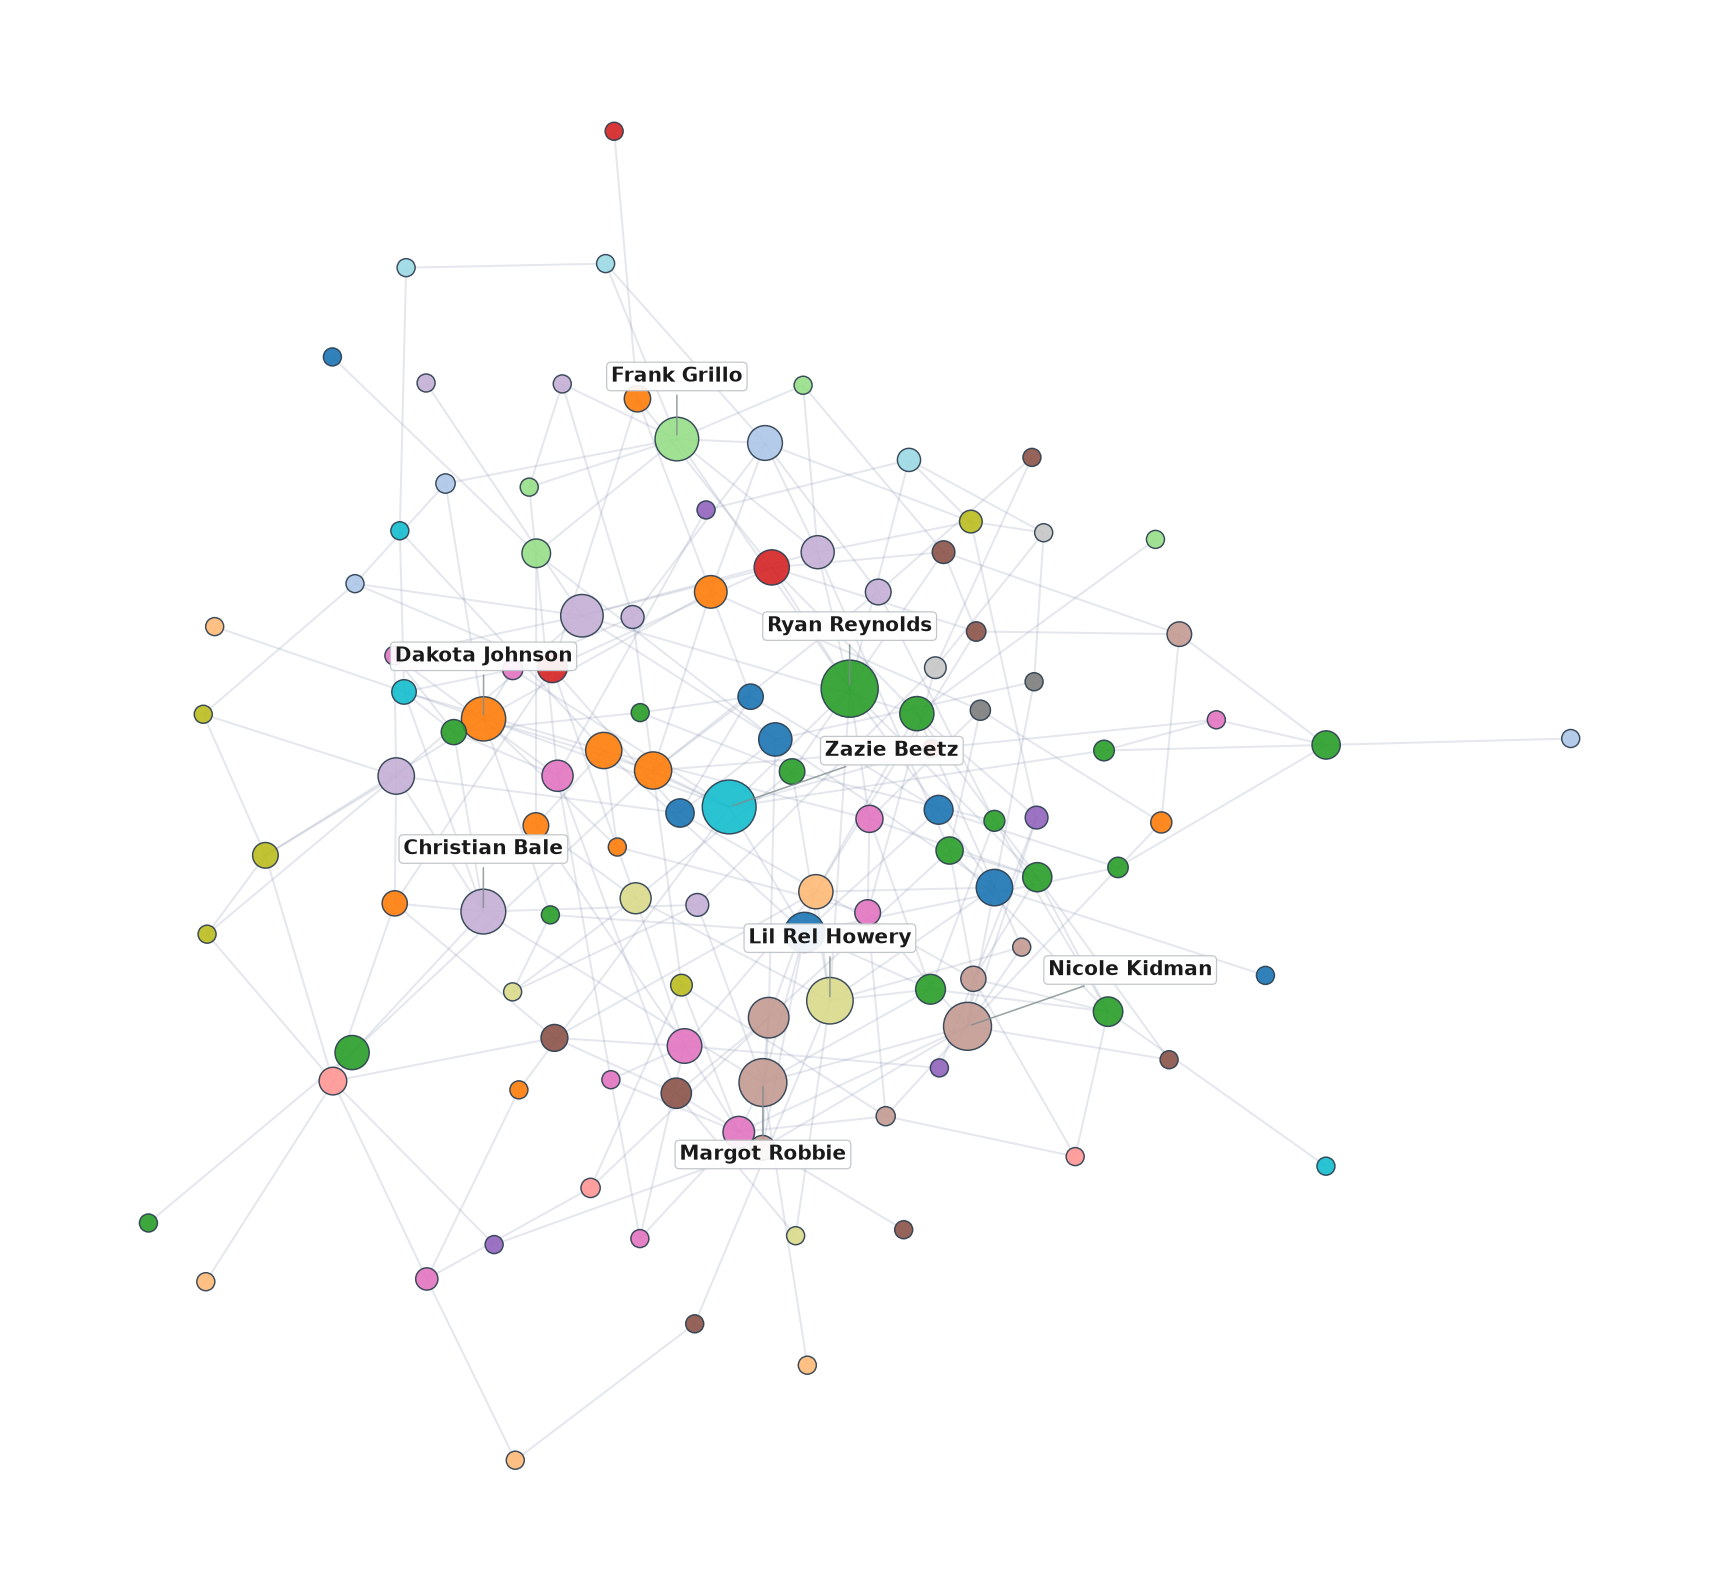

In [9]:
def place_non_overlapping_labels(ax, pos, names, font_size=8.5, base_dy=0.05, min_dx=0.22, min_dy=0.09):
    """Place deterministic non-overlapping rounded pill annotations with leader lines."""
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]
    cx, cy = float(np.mean(xs)), float(np.mean(ys))
    placed = []
    candidate_offsets = [
        (0.0, base_dy), (0.0, -base_dy * 1.15),
        (min_dx * 0.65, base_dy * 0.9), (-min_dx * 0.65, base_dy * 0.9),
        (min_dx * 0.65, -base_dy * 1.1), (-min_dx * 0.65, -base_dy * 1.1),
        (min_dx * 0.95, 0.0), (-min_dx * 0.95, 0.0),
        (0.0, base_dy * 2.1), (0.0, -base_dy * 2.2),
        (min_dx * 0.9, base_dy * 1.8), (-min_dx * 0.9, base_dy * 1.8),
    ]
    for name in sorted(names):
        nx_pos, ny_pos = pos[name]
        best_xy = (nx_pos, ny_pos + base_dy)
        for scale in (1.0, 1.45, 1.95):
            found_slot = False
            for ox, oy in candidate_offsets:
                cand_x, cand_y = nx_pos + ox * scale, ny_pos + oy * scale
                if not any(abs(cand_x - px) < min_dx and abs(cand_y - py) < min_dy for px, py in placed):
                    best_xy = (cand_x, cand_y)
                    found_slot = True
                    break
            if found_slot:
                break
        else:
            dx, dy = nx_pos - cx, ny_pos - cy
            norm = max(np.hypot(dx, dy), 1e-6)
            best_xy = (nx_pos + (dx / norm) * min_dx * 0.9, ny_pos + (dy / norm) * min_dy * 1.4)
        placed.append(best_xy)
        ax.annotate(
            name, xy=(nx_pos, ny_pos), xytext=best_xy,
            fontsize=font_size, fontweight="bold", ha="center", va="center", color="#1a1a1a",
            arrowprops=dict(arrowstyle="-", color="#7f8c8d", lw=0.75, alpha=0.8),
            bbox=dict(boxstyle="round,pad=0.22", facecolor="white", edgecolor="#bdc3c7", alpha=0.92, linewidth=0.6),
            zorder=5,
        )

top_degree_nodes = [node for node, _ in sorted(gcc.degree(), key=lambda x: x[1], reverse=True)[:TOP_CORE_DEGREE_POOL]]
core_raw = gcc.subgraph(top_degree_nodes).copy()
core_gcc_nodes = max(nx.connected_components(core_raw), key=len)
core_subgraph = core_raw.subgraph(core_gcc_nodes).copy()

node_to_comm = {node: cid for cid, c in enumerate(comms) for node in c}
core_bc = nx.betweenness_centrality(core_subgraph)
node_sizes = [max(75, core_bc[n] * 7000) for n in core_subgraph.nodes()]
node_colors = [node_to_comm.get(n, 0) % 20 for n in core_subgraph.nodes()]

fig, ax = plt.subplots(figsize=(11.5, 10.5), dpi=150)
pos = nx.spring_layout(core_subgraph, seed=RANDOM_SEED, k=0.42, iterations=180)
ax.set_aspect("equal")

nx.draw_networkx_edges(core_subgraph, pos, ax=ax, alpha=0.22, edge_color="#8892b0", width=0.95)
nx.draw_networkx_nodes(
    core_subgraph, pos, ax=ax, node_size=node_sizes, node_color=node_colors,
    cmap=plt.cm.tab20, alpha=0.92, edgecolors="#2c3e50", linewidths=0.7
)

top_labeled = [n for n, _ in sorted(core_bc.items(), key=lambda x: x[1], reverse=True)[:8]]
place_non_overlapping_labels(ax, pos, top_labeled, font_size=9.5, base_dy=0.075, min_dx=0.30, min_dy=0.11)

xs, ys = [p[0] for p in pos.values()], [p[1] for p in pos.values()]
ax.set_xlim(min(xs) - 0.16, max(xs) + 0.16)
ax.set_ylim(min(ys) - 0.14, max(ys) + 0.14)
ax.axis("off")
plt.tight_layout(pad=0.3)
plt.show()


### 10. Step 3: Visualization 2 — Girvan-Newman Divisive Decomposition
A 2-panel comparative layout showing Community $C_0$ before and after partitioning:
* **Panel A:** Intact community with the 4 critical Girvan-Newman bridge edges highlighted in bold crimson dashed lines.
* **Panel B:** Decoupled network after 36 edge removals, displaying the 5 isolated sub-communities in distinct categorical colors ($Q = 0.6089$).


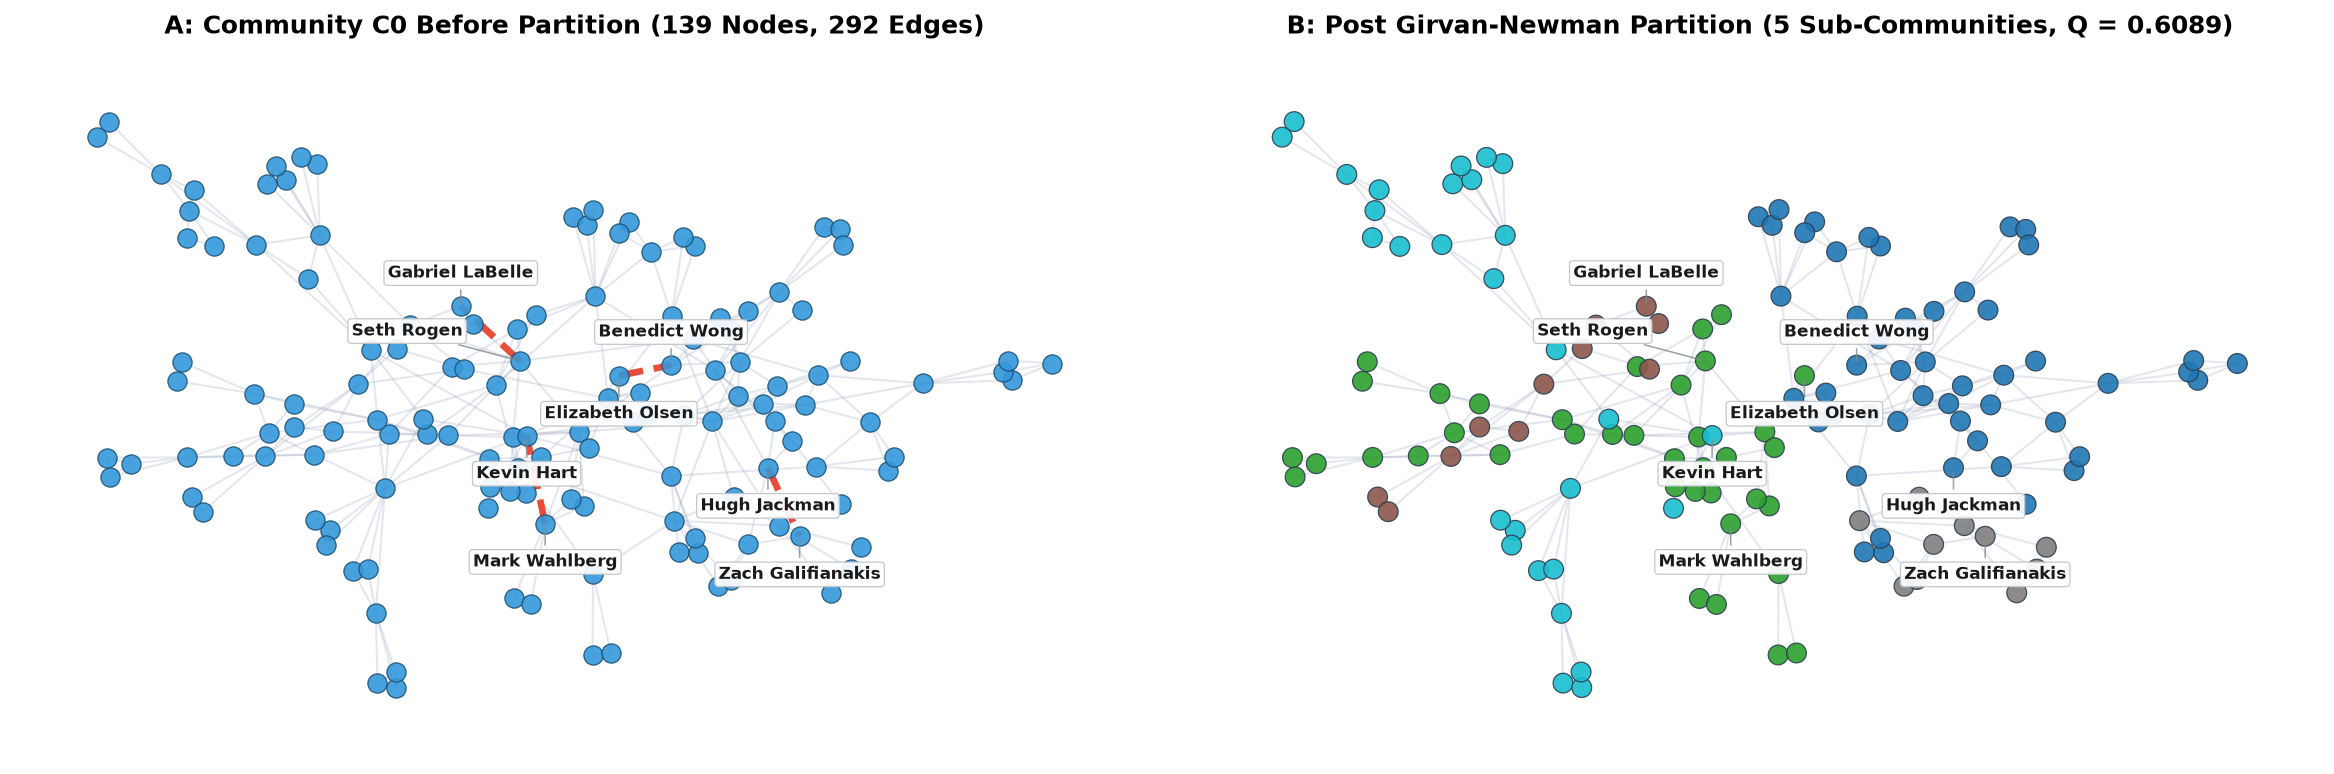

In [10]:
final_comps = list(nx.connected_components(sub))
fig, axes = plt.subplots(1, 2, figsize=(16, 7.2), dpi=150)
pos_c0 = nx.spring_layout(c0, seed=RANDOM_SEED, k=0.33, iterations=140)
axes[0].set_aspect("equal")
axes[1].set_aspect("equal")

axes[0].set_title("A: Community C0 Before Partition (139 Nodes, 292 Edges)", fontsize=12, fontweight="bold", pad=8)
crit_set = {tuple(sorted(e)) for e in critical_edges}
non_crit = [e for e in c0.edges() if tuple(sorted(e)) not in crit_set]
crit_pres = [e for e in c0.edges() if tuple(sorted(e)) in crit_set]
nx.draw_networkx_edges(c0, pos_c0, edgelist=non_crit, ax=axes[0], alpha=0.22, edge_color="#8892b0", width=1.0)
nx.draw_networkx_edges(c0, pos_c0, edgelist=crit_pres, ax=axes[0], edge_color="#e74c3c", width=3.2, style="dashed")
nx.draw_networkx_nodes(c0, pos_c0, ax=axes[0], node_size=85, node_color="#3498db", edgecolors="#1b4f72", linewidths=0.6, alpha=0.90)

labeled_actors = sorted({node for edge in critical_edges for node in edge})
place_non_overlapping_labels(axes[0], pos_c0, labeled_actors, font_size=8.2, base_dy=0.065, min_dx=0.34, min_dy=0.11)
c0_xs, c0_ys = [p[0] for p in pos_c0.values()], [p[1] for p in pos_c0.values()]
axes[0].set_xlim(min(c0_xs) - 0.16, max(c0_xs) + 0.16)
axes[0].set_ylim(min(c0_ys) - 0.14, max(c0_ys) + 0.14)
axes[0].axis("off")

axes[1].set_title("B: Post Girvan-Newman Partition (5 Sub-Communities, Q = 0.6089)", fontsize=12, fontweight="bold", pad=8)
node_comp_map = {n: cid for cid, comp in enumerate(final_comps) for n in comp}
colors_sub = [node_comp_map[n] for n in sub.nodes()]
nx.draw_networkx_edges(sub, pos_c0, ax=axes[1], alpha=0.22, edge_color="#8892b0", width=1.0)
nx.draw_networkx_nodes(sub, pos_c0, ax=axes[1], node_size=90, node_color=colors_sub, cmap=plt.cm.tab10, edgecolors="#2c3e50", linewidths=0.6, alpha=0.90)
place_non_overlapping_labels(axes[1], pos_c0, labeled_actors, font_size=8.2, base_dy=0.065, min_dx=0.34, min_dy=0.11)
axes[1].set_xlim(min(c0_xs) - 0.16, max(c0_xs) + 0.16)
axes[1].set_ylim(min(c0_ys) - 0.14, max(c0_ys) + 0.14)
axes[1].axis("off")

fig.subplots_adjust(wspace=0.06, top=0.92, bottom=0.02, left=0.02, right=0.98)
plt.show()


### 11. Step 3: Visualization 3 — Macro-Topological Distributions & Link Prediction ROC Curves
A 2x2 multi-panel figure examining macro-statistical properties and algorithmic performance:
1. Degree distribution histogram with log-log power-law inset ($P(k) \sim k^{-\gamma}$).
2. Granovetter tie strength distribution ($w=1, 2, 3, 4$).
3. Freeman Betweenness vs. Degree Centrality scatter plot highlighting structural bridges.
4. Link Prediction ROC Curves (Adamic-Adar $\text{AUC} = 0.9851$, Jaccard $\text{AUC} = 0.9852$, Resource Allocation $\text{AUC} = 0.9851$, Preferential Attachment $\text{AUC} = 0.6264$).


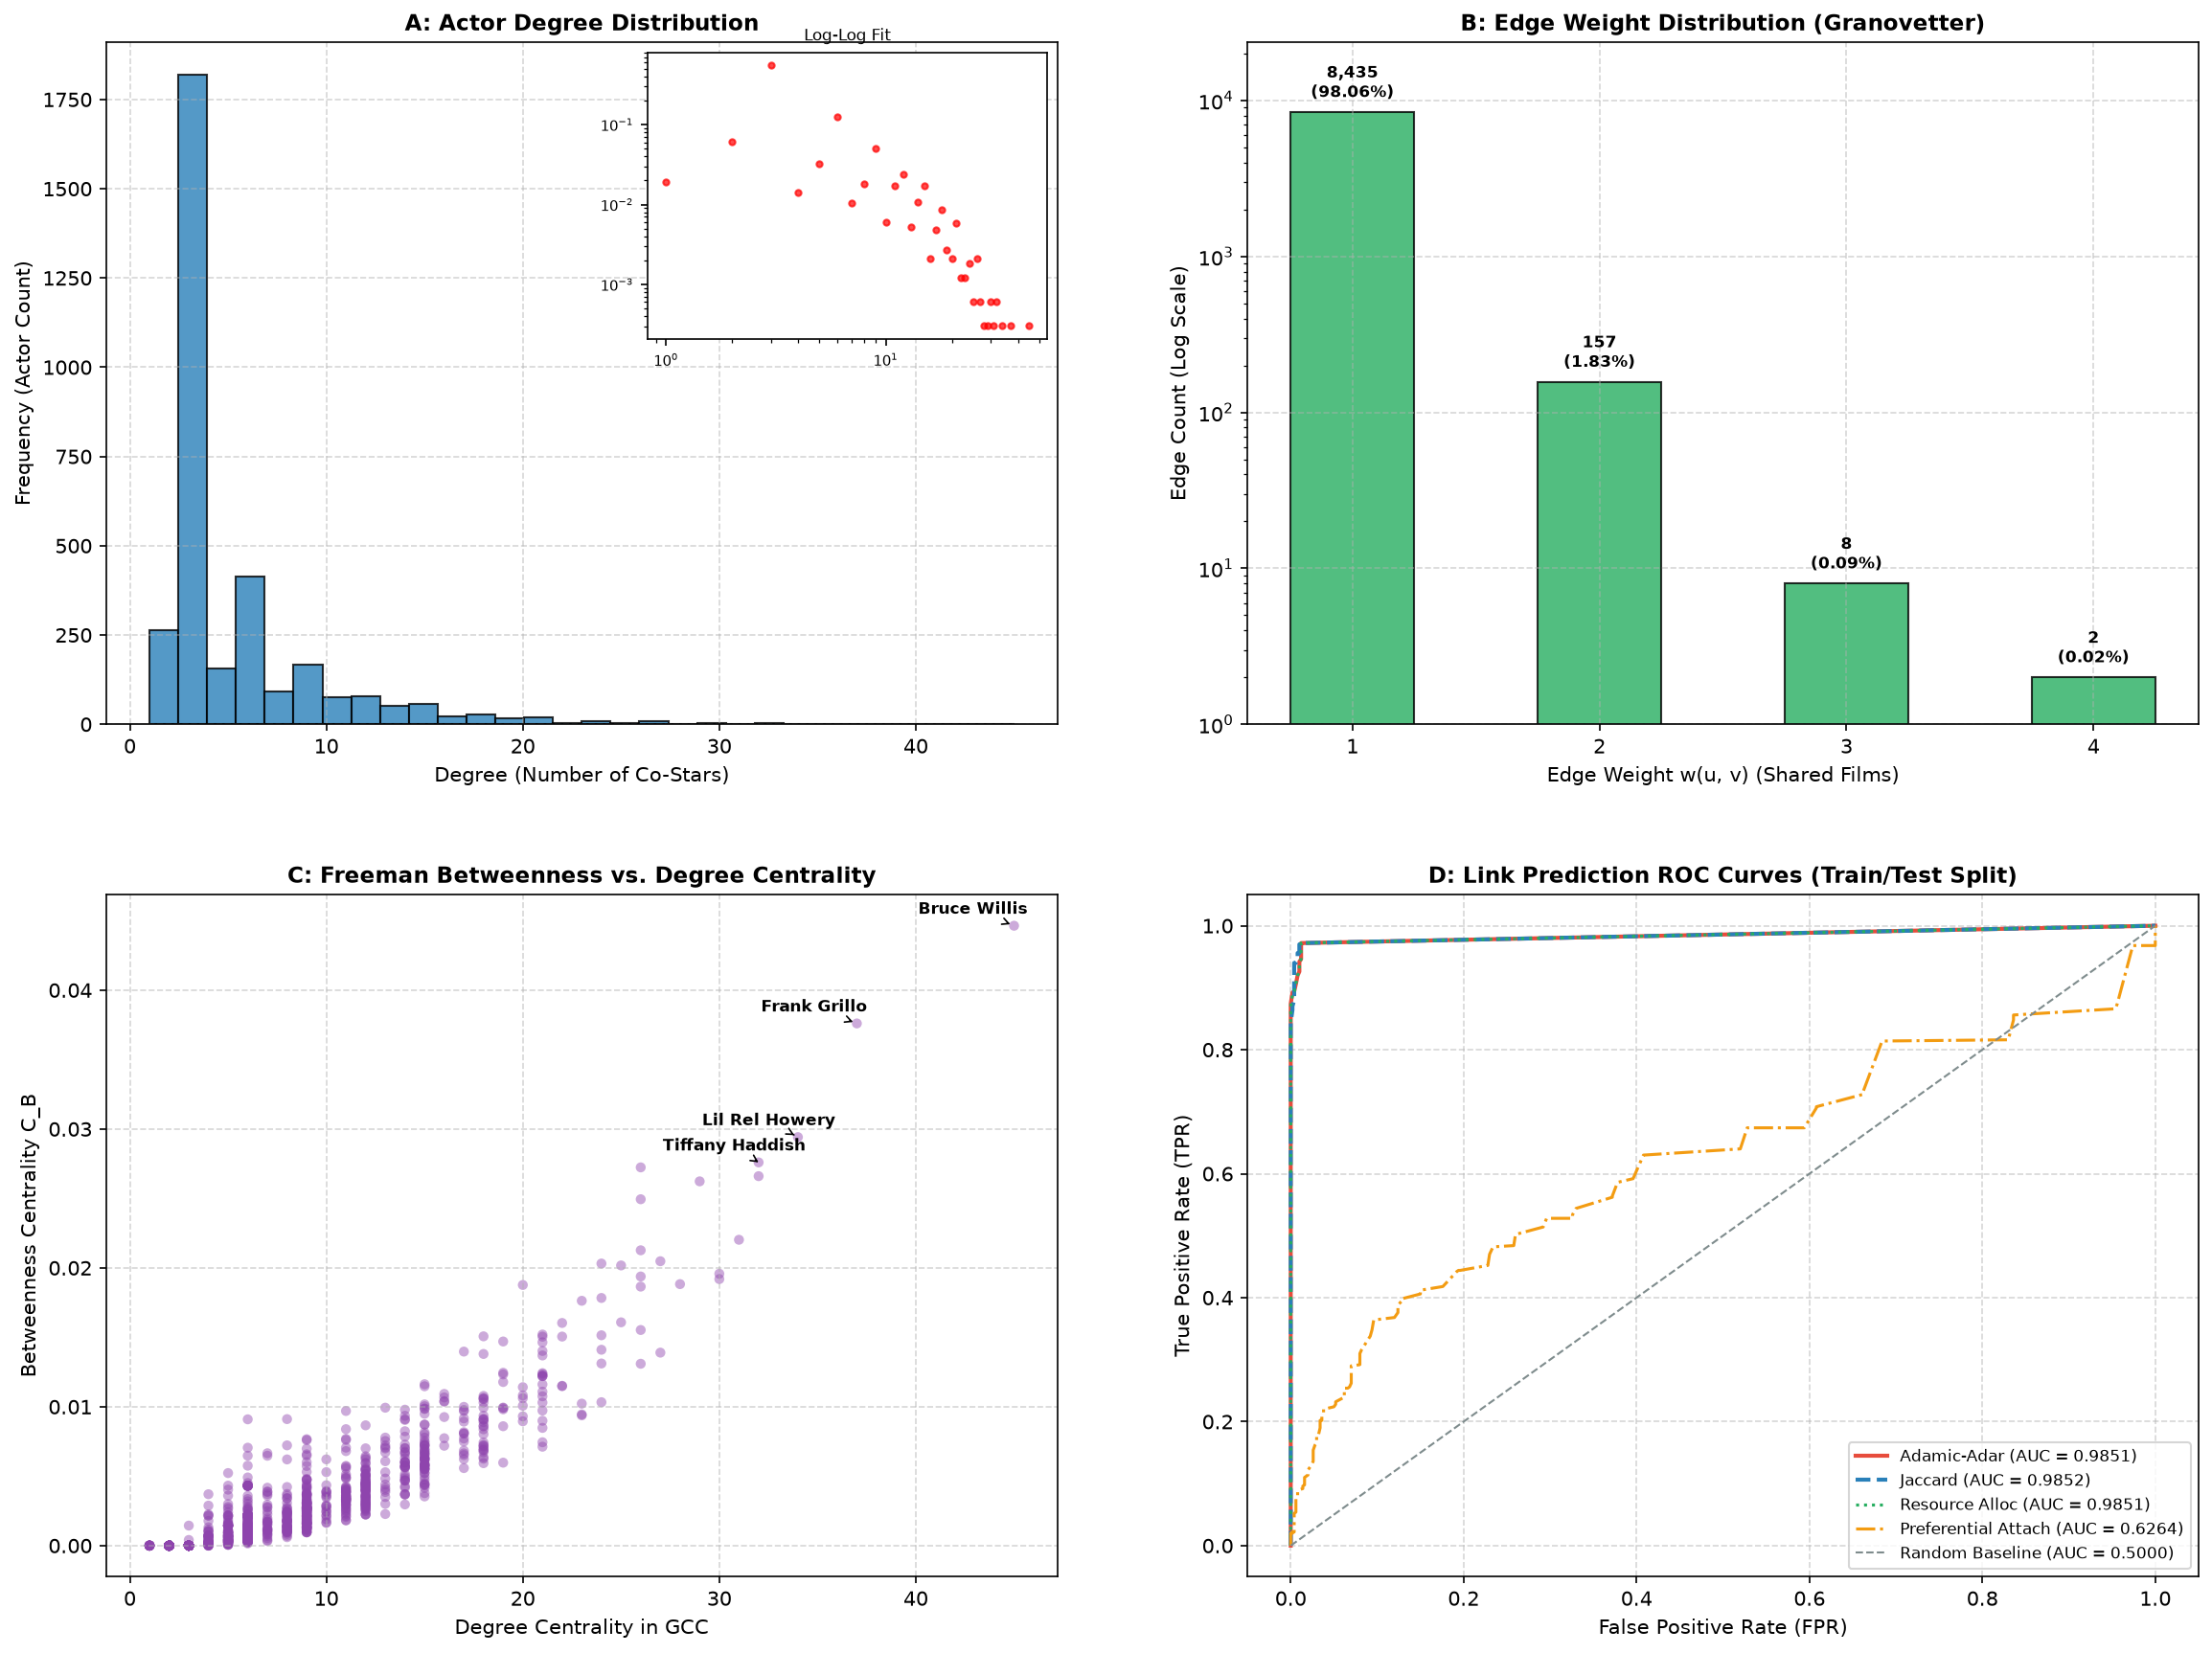

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=150)

# 3A: Degree Distribution
degrees = [d for _, d in G.degree()]
axes[0, 0].hist(degrees, bins=30, color="#2980b9", edgecolor="black", alpha=0.8)
axes[0, 0].set_title("A: Actor Degree Distribution", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Degree (Number of Co-Stars)", fontsize=10)
axes[0, 0].set_ylabel("Frequency (Actor Count)", fontsize=10)
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

ax_inset = inset_axes(axes[0, 0], width="42%", height="42%", loc="upper right")
deg_counts = np.bincount(degrees)
k_vals = np.nonzero(deg_counts)[0]
p_k = deg_counts[k_vals] / len(degrees)
ax_inset.loglog(k_vals, p_k, "ro", markersize=3, alpha=0.7)
ax_inset.set_title("Log-Log Fit", fontsize=8)
ax_inset.tick_params(labelsize=7)

# 3B: Granovetter Tie Strength
weights = [d["weight"] for _, _, d in G.edges(data=True)]
w_counts = Counter(weights)
w_keys = sorted(w_counts.keys())
w_vals = [w_counts[k_w] for k_w in w_keys]
axes[0, 1].bar(w_keys, w_vals, color="#27ae60", edgecolor="black", alpha=0.8, width=0.5)
axes[0, 1].set_yscale("log")
axes[0, 1].set_title("B: Edge Weight Distribution (Granovetter)", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Edge Weight w(u, v) (Shared Films)", fontsize=10)
axes[0, 1].set_ylabel("Edge Count (Log Scale)", fontsize=10)
axes[0, 1].set_xticks(w_keys)
axes[0, 1].set_ylim(1, max(w_vals) * 2.8)
for k_val, v_val in zip(w_keys, w_vals):
    axes[0, 1].text(k_val, v_val * 1.25, f"{v_val:,}\n({v_val/len(weights)*100:.2f}%)", ha="center", fontsize=8, fontweight="bold")
axes[0, 1].grid(True, linestyle="--", alpha=0.5)

# 3C: Betweenness vs Degree
bc_vals = [bc.get(n, 0) for n in gcc.nodes()]
deg_gcc = [gcc.degree(n) for n in gcc.nodes()]
axes[1, 0].scatter(deg_gcc, bc_vals, alpha=0.45, color="#8e44ad", edgecolors="none", s=25)
axes[1, 0].set_title("C: Freeman Betweenness vs. Degree Centrality", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Degree Centrality in GCC", fontsize=10)
axes[1, 0].set_ylabel("Betweenness Centrality C_B", fontsize=10)
axes[1, 0].grid(True, linestyle="--", alpha=0.5)

top_bridges = sorted(bc.items(), key=lambda x: x[1], reverse=True)[:4]
for name, val in top_bridges:
    d_val = gcc.degree(name)
    axes[1, 0].annotate(name, (d_val, val), textcoords="offset points", xytext=(-48, 6),
                        fontsize=8, fontweight="bold", arrowprops=dict(arrowstyle="->", lw=0.8, color="black"))

# 3D: Link Prediction ROC Curves
fpr_aa, tpr_aa, _ = roc_curve(y_true, aa_scores)
fpr_j, tpr_j, _ = roc_curve(y_true, j_scores)
fpr_ra, tpr_ra, _ = roc_curve(y_true, ra_scores)
fpr_pa, tpr_pa, _ = roc_curve(y_true, pa_scores)

axes[1, 1].plot(fpr_aa, tpr_aa, color="#e74c3c", lw=2.0, label=f"Adamic-Adar (AUC = {auc_aa:.4f})")
axes[1, 1].plot(fpr_j, tpr_j, color="#2980b9", lw=2.0, linestyle="--", label=f"Jaccard (AUC = {auc_j:.4f})")
axes[1, 1].plot(fpr_ra, tpr_ra, color="#27ae60", lw=1.5, linestyle=":", label=f"Resource Alloc (AUC = {auc_ra:.4f})")
axes[1, 1].plot(fpr_pa, tpr_pa, color="#f39c12", lw=1.5, linestyle="-.", label=f"Preferential Attach (AUC = {auc_pa:.4f})")
axes[1, 1].plot([0, 1], [0, 1], color="#7f8c8d", lw=1.0, linestyle="--", label="Random Baseline (AUC = 0.5000)")

axes[1, 1].set_title("D: Link Prediction ROC Curves (Train/Test Split)", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("False Positive Rate (FPR)", fontsize=10)
axes[1, 1].set_ylabel("True Positive Rate (TPR)", fontsize=10)
axes[1, 1].legend(loc="lower right", fontsize=8)
axes[1, 1].grid(True, linestyle="--", alpha=0.5)

fig.subplots_adjust(hspace=0.25, wspace=0.20, left=0.06, right=0.97, top=0.95, bottom=0.06)
plt.show()
